In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import requests

from pathlib import Path
from scipy.stats import ttest_ind
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.metrics import mean_absolute_error, mean_squared_error
from econml.dml import CausalForestDML

In [5]:
SEED = 42

DATA_DIR = Path("data/raw")
PROCESSED_DIR = Path("data/processed")
MODEL_DIR = Path("models/causal")
METRICS_DIR = Path("artifacts/metrics")
FIGURES_DIR = Path("artifacts/figures")
REPORTS_DIR = Path("artifacts/reports")

for folder in [
    DATA_DIR,
    PROCESSED_DIR,
    MODEL_DIR,
    METRICS_DIR,
    FIGURES_DIR,
    REPORTS_DIR
]:
    folder.mkdir(parents=True, exist_ok=True)

In [7]:
url = "https://raw.githubusercontent.com/AdityaDabrase/ab-testing-email-marketing/main/data/raw/hillstrom.csv"

file_path = DATA_DIR / "hillstrom.csv"

if not file_path.exists():
    response = requests.get(url, timeout=60)
    response.raise_for_status()
    file_path.write_bytes(response.content)

df = pd.read_csv(file_path)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (64000, 12)


,recency,history_segment,history,mens,womens,zip_code,newbie,channel,segment,visit,conversion,spend
0,10,2) $100 - $200,142.44,1,0,Surburban,0,Phone,Womens E-Mail,0,0,0.0
1,6,3) $200 - $350,329.08,1,1,Rural,1,Web,No E-Mail,0,0,0.0
2,7,2) $100 - $200,180.65,0,1,Surburban,1,Web,Womens E-Mail,0,0,0.0
3,9,5) $500 - $750,675.83,1,0,Rural,1,Web,Mens E-Mail,0,0,0.0
4,2,1) $0 - $100,45.34,1,0,Urban,0,Web,Womens E-Mail,0,0,0.0


In [9]:
print("Columns:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
display(df.isna().sum().to_frame("missing_values"))

print("\nTreatment groups:")
display(df["segment"].value_counts())

print("\nOutcome summary:")
display(df[["conversion", "spend"]].describe())

Columns:
['recency', 'history_segment', 'history', 'mens', 'womens', 'zip_code', 'newbie', 'channel', 'segment', 'visit', 'conversion', 'spend']

Data types:
recency              int64
history_segment     object
history            float64
mens                 int64
womens               int64
zip_code            object
newbie               int64
channel             object
segment             object
visit                int64
conversion           int64
spend              float64
dtype: object

Missing values:


,missing_values
recency,0
history_segment,0
history,0
mens,0
womens,0
zip_code,0
newbie,0
channel,0
segment,0
visit,0



Treatment groups:


segment
Womens E-Mail    21387
Mens E-Mail      21307
No E-Mail        21306
Name: count, dtype: int64


Outcome summary:


,conversion,spend
count,64000.000000,64000.000000
mean,0.009031,1.050908
std,0.094604,15.036448
min,0.000000,0.000000
25%,0.000000,0.000000
50%,0.000000,0.000000
75%,0.000000,0.000000
max,1.000000,499.000000


In [10]:
required_columns = [
    "segment",
    "conversion",
    "spend"
]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    raise ValueError(f"Missing columns: {missing_columns}")

df = df.dropna(subset=required_columns).copy()

print("Dataset shape:", df.shape)
print("Treatment groups:", df["segment"].unique())
print("Conversion values:", df["conversion"].unique())
print("Missing values:")
display(df.isna().sum())

Dataset shape: (64000, 12)
Treatment groups: ['Womens E-Mail' 'No E-Mail' 'Mens E-Mail']
Conversion values: [0 1]
Missing values:


recency            0
history_segment    0
history            0
mens               0
womens             0
zip_code           0
newbie             0
channel            0
segment            0
visit              0
conversion         0
spend              0
dtype: int64

In [11]:
treatment_value = "Mens E-Mail"
control_value = "No E-Mail"

experiment_df = df[
    df["segment"].isin([treatment_value, control_value])
].copy()

experiment_df["treatment"] = (
    experiment_df["segment"] == treatment_value
).astype(int)

print("Experiment size:", len(experiment_df))
print("Treatment customers:", (experiment_df["treatment"] == 1).sum())
print("Control customers:", (experiment_df["treatment"] == 0).sum())

display(experiment_df.head())

Experiment size: 42613
Treatment customers: 21307
Control customers: 21306


,recency,history_segment,history,mens,womens,zip_code,newbie,channel,segment,visit,conversion,spend,treatment
1,6,3) $200 - $350,329.08,1,1,Rural,1,Web,No E-Mail,0,0,0.0,0
3,9,5) $500 - $750,675.83,1,0,Rural,1,Web,Mens E-Mail,0,0,0.0,1
8,9,5) $500 - $750,675.07,1,1,Rural,1,Phone,Mens E-Mail,0,0,0.0,1
13,2,2) $100 - $200,101.64,0,1,Urban,0,Web,Mens E-Mail,1,0,0.0,1
14,4,3) $200 - $350,241.42,0,1,Rural,1,Multichannel,No E-Mail,0,0,0.0,0


In [12]:
excluded_columns = [
    "segment",
    "conversion",
    "spend",
    "treatment"
]

feature_cols = [
    col for col in experiment_df.columns
    if col not in excluded_columns
    and pd.api.types.is_numeric_dtype(experiment_df[col])
]

print("Selected features:", feature_cols)

X = experiment_df[feature_cols].copy()
T = experiment_df["treatment"].to_numpy()
Y = experiment_df["conversion"].astype(int).to_numpy()

print("Feature shape:", X.shape)
print("Treatment shape:", T.shape)
print("Outcome shape:", Y.shape)

Selected features: ['recency', 'history', 'mens', 'womens', 'newbie', 'visit']
Feature shape: (42613, 6)
Treatment shape: (42613,)
Outcome shape: (42613,)


In [13]:
control = experiment_df.loc[
    experiment_df["treatment"] == 0, "conversion"
]

treated = experiment_df.loc[
    experiment_df["treatment"] == 1, "conversion"
]

control_rate = control.mean()
treatment_rate = treated.mean()

observed_effect = treatment_rate - control_rate

test_result = ttest_ind(
    treated,
    control,
    equal_var=False
)

print("Control conversion rate:", round(control_rate, 4))
print("Treatment conversion rate:", round(treatment_rate, 4))
print("Observed conversion difference:", round(observed_effect, 4))
print("P-value:", round(test_result.pvalue, 6))
print("Statistically significant at 5%:", test_result.pvalue < 0.05)

Control conversion rate: 0.0057
Treatment conversion rate: 0.0125
Observed conversion difference: 0.0068
P-value: 0.0
Statistically significant at 5%: True


In [14]:
X_train, X_test, T_train, T_test, Y_train, Y_test = train_test_split(
    X,
    T,
    Y,
    test_size=0.25,
    random_state=42,
    stratify=T
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 31959
Testing samples: 10654


In [15]:
propensity_model = LogisticRegression(max_iter=2000)

propensity_model.fit(X_train, T_train)

propensity_scores = propensity_model.predict_proba(X_test)[:, 1]

print("Minimum propensity:", round(propensity_scores.min(), 4))
print("Maximum propensity:", round(propensity_scores.max(), 4))
print("Mean propensity:", round(propensity_scores.mean(), 4))

Minimum propensity: 0.4455
Maximum propensity: 0.6576
Mean propensity: 0.5003


/Users/naitikdonda/tf-env/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/naitikdonda/tf-env/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/naitikdonda/tf-env/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/naitikdonda/tf-env/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/naitikdonda/tf-env/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/naitikdonda/tf-env/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul

In [16]:
s_model = RandomForestRegressor(
    n_estimators=200,
    min_samples_leaf=10,
    random_state=42,
    n_jobs=-1
)

X_train_s = X_train.copy()
X_train_s["treatment"] = T_train

X_test_control = X_test.copy()
X_test_control["treatment"] = 0

X_test_treated = X_test.copy()
X_test_treated["treatment"] = 1

s_model.fit(X_train_s, Y_train)

s_y0 = s_model.predict(X_test_control)
s_y1 = s_model.predict(X_test_treated)

cate_s = s_y1 - s_y0

print("S-learner estimated ATE:", round(cate_s.mean(), 4))

S-learner estimated ATE: 0.0018


In [17]:
t_model_control = RandomForestRegressor(
    n_estimators=200,
    min_samples_leaf=10,
    random_state=42,
    n_jobs=-1
)

t_model_treated = RandomForestRegressor(
    n_estimators=200,
    min_samples_leaf=10,
    random_state=43,
    n_jobs=-1
)

t_model_control.fit(
    X_train[T_train == 0],
    Y_train[T_train == 0]
)

t_model_treated.fit(
    X_train[T_train == 1],
    Y_train[T_train == 1]
)

t_y0 = t_model_control.predict(X_test)
t_y1 = t_model_treated.predict(X_test)

cate_t = t_y1 - t_y0

print("T-learner estimated ATE:", round(cate_t.mean(), 4))

T-learner estimated ATE: 0.0027


In [18]:
x_tau_control = (
    t_model_treated.predict(X_train[T_train == 0])
    - Y_train[T_train == 0]
)

x_tau_treated = (
    Y_train[T_train == 1]
    - t_model_control.predict(X_train[T_train == 1])
)

x_model_control = RandomForestRegressor(
    n_estimators=200,
    min_samples_leaf=10,
    random_state=44,
    n_jobs=-1
)

x_model_treated = RandomForestRegressor(
    n_estimators=200,
    min_samples_leaf=10,
    random_state=45,
    n_jobs=-1
)

x_model_control.fit(X_train[T_train == 0], x_tau_control)
x_model_treated.fit(X_train[T_train == 1], x_tau_treated)

x_cate_control = x_model_control.predict(X_test)
x_cate_treated = x_model_treated.predict(X_test)

x_propensity = propensity_model.predict_proba(X_test)[:, 1]

cate_x = (
    x_propensity * x_cate_control
    + (1 - x_propensity) * x_cate_treated
)

print("X-learner estimated ATE:", round(cate_x.mean(), 4))

X-learner estimated ATE: 0.0028


/Users/naitikdonda/tf-env/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/naitikdonda/tf-env/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/naitikdonda/tf-env/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b


In [19]:
causal_forest = CausalForestDML(
    model_y=RandomForestRegressor(
        n_estimators=100,
        min_samples_leaf=10,
        random_state=42,
        n_jobs=-1
    ),
    model_t=RandomForestClassifier(
        n_estimators=100,
        min_samples_leaf=10,
        random_state=42,
        n_jobs=-1
    ),
    discrete_treatment=True,
    n_estimators=200,
    min_samples_leaf=10,
    random_state=42,
    n_jobs=-1
)

causal_forest.fit(
    Y_train,
    T_train,
    X=X_train
)

cate_forest = np.asarray(
    causal_forest.effect(X_test)
).reshape(-1)

print("Causal Forest estimated ATE:", round(cate_forest.mean(), 4))

Causal Forest estimated ATE: 0.0027


In [20]:
naive_ate = (
    Y_test[T_test == 1].mean()
    - Y_test[T_test == 0].mean()
)

ate_results = pd.DataFrame({
    "method": [
        "Naive Difference",
        "S-learner",
        "T-learner",
        "X-learner",
        "Causal Forest"
    ],
    "estimated_ate": [
        naive_ate,
        cate_s.mean(),
        cate_t.mean(),
        cate_x.mean(),
        cate_forest.mean()
    ]
})

display(ate_results.round(5))

,method,estimated_ate
0,Naive Difference,0.00657
1,S-learner,0.00182
2,T-learner,0.00271
3,X-learner,0.00281
4,Causal Forest,0.00267


In [21]:
cate_predictions = {
    "S-learner": cate_s,
    "T-learner": cate_t,
    "X-learner": cate_x,
    "Causal Forest": cate_forest
}

cate_metrics = pd.DataFrame([
    {
        "model": name,
        "estimated_ate": float(prediction.mean()),
        "minimum_cate": float(prediction.min()),
        "maximum_cate": float(prediction.max()),
        "positive_effect_share": float((prediction > 0).mean()),
        "negative_effect_share": float((prediction < 0).mean())
    }
    for name, prediction in cate_predictions.items()
])

display(cate_metrics.round(5))

,model,estimated_ate,minimum_cate,maximum_cate,positive_effect_share,negative_effect_share
0,S-learner,0.00182,-0.11488,0.17028,0.09142,0.05566
1,T-learner,0.00271,-0.17172,0.29434,0.08673,0.06035
2,X-learner,0.00281,-0.15490,0.21431,0.10785,0.06589
3,Causal Forest,0.00267,-0.09496,0.10226,0.11047,0.04233


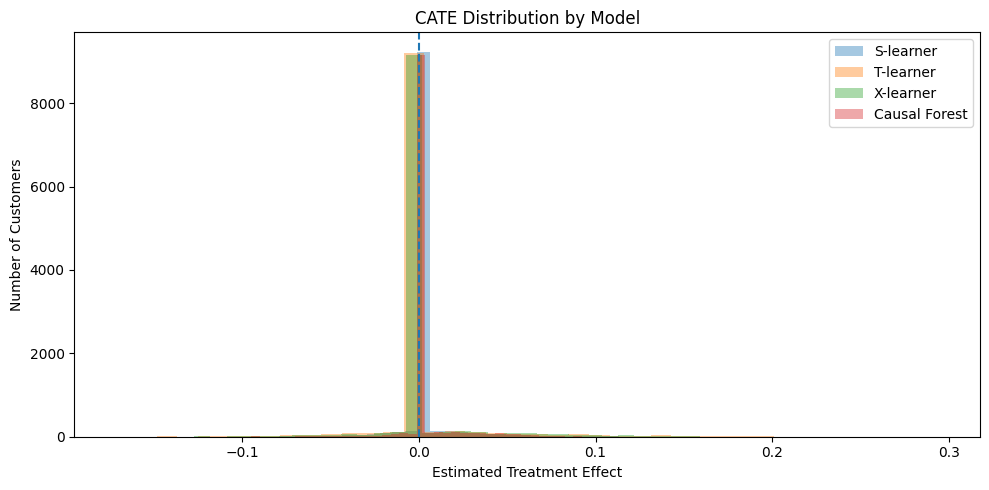

In [22]:
plt.figure(figsize=(10, 5))

for name, prediction in cate_predictions.items():
    plt.hist(prediction, bins=40, alpha=0.4, label=name)

plt.axvline(0, linestyle="--")
plt.xlabel("Estimated Treatment Effect")
plt.ylabel("Number of Customers")
plt.title("CATE Distribution by Model")
plt.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "cate_distribution.png", dpi=150)
plt.show()

In [23]:
segment_df = X_test.copy()

segment_df["estimated_cate"] = cate_forest
segment_df["treatment"] = T_test
segment_df["conversion"] = Y_test

segment_df["loyalty_segment"] = pd.qcut(
    segment_df["loyalty_score"],
    q=3,
    labels=["Low Loyalty", "Medium Loyalty", "High Loyalty"],
    duplicates="drop"
) if "loyalty_score" in segment_df.columns else "All Customers"

segment_results = segment_df.groupby(
    "loyalty_segment",
    observed=True
).agg(
    customers=("conversion", "size"),
    estimated_cate=("estimated_cate", "mean"),
    positive_effect_share=(
        "estimated_cate",
        lambda x: (x > 0).mean()
    )
).reset_index()

display(segment_results.round(4))

,loyalty_segment,customers,estimated_cate,positive_effect_share
0,All Customers,10654,0.0027,0.1105


In [24]:
conversion_by_segment = segment_df.groupby(
    ["loyalty_segment", "treatment"],
    observed=True
)["conversion"].agg(
    ["mean", "count"]
).reset_index()

conversion_by_segment["group"] = conversion_by_segment[
    "treatment"
].map({0: "Control", 1: "Treatment"})

display(conversion_by_segment)

,loyalty_segment,treatment,mean,count,group
0,All Customers,0,0.006383,5327,Control
1,All Customers,1,0.012953,5327,Treatment


In [25]:
experiment_df.to_csv(
    PROCESSED_DIR / "hillstrom_experiment.csv",
    index=False
)

ate_results.to_csv(
    METRICS_DIR / "ate_comparison.csv",
    index=False
)

cate_metrics.to_csv(
    METRICS_DIR / "cate_model_summaries.csv",
    index=False
)

segment_results.to_csv(
    METRICS_DIR / "segment_effects.csv",
    index=False
)

print("Saved experiment data and metrics.")

Saved experiment data and metrics.


In [26]:
joblib.dump(
    {
        "propensity_model": propensity_model,
        "s_learner": s_model,
        "t_learner_control": t_model_control,
        "t_learner_treated": t_model_treated,
        "x_learner_control": x_model_control,
        "x_learner_treated": x_model_treated,
        "causal_forest": causal_forest,
        "feature_cols": feature_cols
    },
    MODEL_DIR / "causal_models.joblib"
)

print("Causal models saved successfully.")

Causal models saved successfully.


In [27]:
import json

summary = {
    "dataset": "Hillstrom Email Marketing Experiment",
    "treatment_group": treatment_value,
    "control_group": control_value,
    "outcome": "conversion",
    "total_customers": int(len(experiment_df)),
    "treatment_customers": int((T == 1).sum()),
    "control_customers": int((T == 0).sum()),
    "control_conversion_rate": float(control.mean()),
    "treatment_conversion_rate": float(treated.mean()),
    "observed_conversion_difference": float(observed_effect),
    "test_set_naive_ate": float(naive_ate),
    "estimated_ate_models": {
        name: float(prediction.mean())
        for name, prediction in cate_predictions.items()
    }
}

with open(REPORTS_DIR / "experiment_summary.json", "w") as f:
    json.dump(summary, f, indent=4)

print(json.dumps(summary, indent=4))

{
    "dataset": "Hillstrom Email Marketing Experiment",
    "treatment_group": "Mens E-Mail",
    "control_group": "No E-Mail",
    "outcome": "conversion",
    "total_customers": 42613,
    "treatment_customers": 21307,
    "control_customers": 21306,
    "control_conversion_rate": 0.005726086548390125,
    "treatment_conversion_rate": 0.01253109306800582,
    "observed_conversion_difference": 0.006805006519615695,
    "test_set_naive_ate": 0.006570302233902759,
    "estimated_ate_models": {
        "S-learner": 0.0018232377277174203,
        "T-learner": 0.002712467240631539,
        "X-learner": 0.002808308840849032,
        "Causal Forest": 0.002665919891603035
    }
}


In [28]:
expected_files = [
    PROCESSED_DIR / "hillstrom_experiment.csv",
    METRICS_DIR / "ate_comparison.csv",
    METRICS_DIR / "cate_model_summaries.csv",
    METRICS_DIR / "segment_effects.csv",
    MODEL_DIR / "causal_models.joblib",
    REPORTS_DIR / "experiment_summary.json",
    FIGURES_DIR / "cate_distribution.png"
]

for file_path in expected_files:
    print(
        file_path,
        "EXISTS" if file_path.exists() else "MISSING"
    )

data/processed/hillstrom_experiment.csv EXISTS
artifacts/metrics/ate_comparison.csv EXISTS
artifacts/metrics/cate_model_summaries.csv EXISTS
artifacts/metrics/segment_effects.csv EXISTS
models/causal/causal_models.joblib EXISTS
artifacts/reports/experiment_summary.json EXISTS
artifacts/figures/cate_distribution.png EXISTS


In [ ]:
print("Dataset:", "Hillstrom Email Marketing Experiment")
print("Treatment:", treatment_value)
print("Control:", control_value)
print("Outcome:", "conversion")
print("Customers:", len(experiment_df))
print("Features:", len(feature_cols))

print("\nEstimated ATE by model:")
display(ate_results.round(5))

print("\nCustomer segments:")
display(segment_results.round(4))

print("\nNotebook 1 processing completed.")

Dataset: Hillstrom Email Marketing Experiment
Treatment: Mens E-Mail
Control: No E-Mail
Outcome: conversion
Customers: 42613
Features: 6

Estimated ATE by model:


,method,estimated_ate
0,Naive Difference,0.00657
1,S-learner,0.00182
2,T-learner,0.00271
3,X-learner,0.00281
4,Causal Forest,0.00267



Customer segments:


,loyalty_segment,customers,estimated_cate,positive_effect_share
0,All Customers,10654,0.0027,0.1105



Notebook 1 processing completed.
